# 01 - Data review and data dictionary
MovieLens small dataset. This notebook describes the data (source, terms of use, variables), checks its quality, and looks at ratings per user/movie, popular movies, tags and the time range, before any modelling. Run top to bottom from the `notebooks/` folder. Figures used in the report are saved to `reports/figures/`.

In [12]:
import json
import os
import sys

sys.path.append("..")   # so we can import recsys (this notebook is in notebooks/)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from recsys.data import load_data, quality_report

FIG_DIR = "../reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)

movies, ratings, tags, links = load_data()
print(len(movies), len(ratings), len(tags), len(links))

9742 100836 3683 9742


# Data dictionary

## Source
- **Dataset:** MovieLens Latest Small (`ml-latest-small`), GroupLens Research, University of Minnesota
- **Page:** https://grouplens.org/datasets/movielens/latest/
- **Download:** https://files.grouplens.org/datasets/movielens/ml-latest-small.zip
- **Get it:** `python scripts/get_data.py` (add `--force` to download again). The script saves the files in `data_raw/`, checks the row counts and writes `data_raw/DATA_SOURCE.json`.
- **Access date:** the date of the last download, recorded in `DATA_SOURCE.json` (shown below). If it says "unknown", run `get_data.py --force` once.

In [13]:
print(open("../data_raw/DATA_SOURCE.json").read())

{
  "url": "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip",
  "access_date": "2026-10-28",
  "rows": {
    "movies.csv": 9742,
    "ratings.csv": 100836,
    "tags.csv": 3683,
    "links.csv": 9742
  }
}


## Terms of use (summary from Dataset README)
- Research use only. No commercial use without permission from GroupLens.
- Cite the dataset in reports and publications:
  F. M. Harper and J. A. Konstan. 2015. The MovieLens Datasets: History and Context. *ACM Transactions on Interactive Intelligent Systems* 5(4), Article 19. https://doi.org/10.1145/2827872
- The data can be redistributed (also after changes) only under the same conditions, so keep the license text next to the CSVs.
- No warranty.

## Files and variables

**`ratings.csv`** (main interaction data)

| Column | Description |
|---|---|
| `userId` | anonymous user id, same ids in `tags.csv` |
| `movieId` | movie id, joins to the other files |
| `rating` | stars from 0.5 to 5.0 in steps of 0.5. Ratings of 4.0 or higher count as "liked"|
| `timestamp` | seconds since 1970-01-01 UTC. |

**`movies.csv`**

| Column | Description |
|---|---|
| `movieId` | primary key |
| `title` | title with release year in brackets, e.g. `Toy Story (1995)`. Typed by hand, so it can be inconsistent |
| `genres` | genres separated by `\|`, or `(no genres listed)` |
| `year` | *added in `load_data()`:* release year taken from the title |
| `genre_list` | *added in `load_data()`:* `genres` split into a list |

**`tags.csv`** (free text tags)

| Column | Description |
|---|---|
| `userId`, `movieId` | who put which tag on which movie |
| `tag` | free text. `load_data()` makes it lowercase and strips spaces (the original is kept in `tag_raw`) |
| `timestamp` | when the tag was added |

**`links.csv`**

| Column | Description |
|---|---|
| `movieId` | primary key |
| `imdbId` | IMDb id |
| `tmdbId` | The Movie Database id, some are missing |

`load_data()` also adds a `date` column (readable version of `timestamp`) to ratings and tags.

## Data quality
Checks for missing values, duplicates, invalid ratings and ids that don't match. No rows are dropped, the raw files are not changed.

In [14]:
report = quality_report(movies, ratings, tags, links)
with open("../reports/data_quality.json", "w") as f:
    json.dump(report, f, indent=2)

checks = {
    "missing values in ratings and tags": sum(len(report["missing_values"][k]) for k in ["ratings", "tags"]),
    "duplicate (user, movie) ratings": report["duplicates"]["ratings_user_movie_pairs"],
    "rating values not in 0.5 to 5.0": report["invalid_rating_values"],
    "ratings with unknown movieId": report["referential_integrity"]["ratings_movieIds_not_in_movies"],
    "tags with unknown movieId": report["referential_integrity"]["tags_movieIds_not_in_movies"],
    "movies with no ratings": report["referential_integrity"]["movies_with_no_ratings"],
    "movies where the year was not found": report["movies"]["year_unparsed"],
    "movies with no genres listed": report["movies"]["no_genres_listed"],
    "links with missing tmdbId": report["missing_values"]["links"].get("tmdbId", 0),
    "movie titles used more than once": report["duplicates"]["movie_titles_in_movies"],
    "tags on a movie the same user did not rate": report["tags"]["tags_on_movie_user_did_not_rate"],
}
pd.Series(checks, name="count")

missing values in ratings and tags              0
duplicate (user, movie) ratings                 0
rating values not in 0.5 to 5.0                 0
ratings with unknown movieId                    0
tags with unknown movieId                       0
movies with no ratings                         18
movies where the year was not found            13
movies with no genres listed                   34
links with missing tmdbId                       8
movie titles used more than once                5
tags on a movie the same user did not rate    207
Name: count, dtype: int64

In [15]:
for key in ["users", "movies", "tags"]:
    print(key, json.dumps(report[key], indent=2))

users {
  "n": 610,
  "min_ratings": 20,
  "median_ratings": 70.5,
  "max_ratings": 2698,
  "share_with_all_ratings_in_one_day": 0.593,
  "share_ratings_from_top_10pct_users": 0.477
}
movies {
  "n_catalog": 9742,
  "n_rated": 9724,
  "median_ratings": 3.0,
  "share_with_1_rating": 0.354,
  "share_under_5_ratings": 0.625,
  "share_ratings_on_top_1pct_movies": 0.157,
  "no_genres_listed": 34,
  "year_unparsed": 13
}
tags {
  "n_applications": 3683,
  "n_users_who_tagged": 58,
  "n_movies_tagged": 1572,
  "n_distinct_tags_raw": 1589,
  "n_distinct_tags_normalised": 1475,
  "tags_on_movie_user_did_not_rate": 207,
  "share_tags_by_top_user": 0.409
}


## Ratings

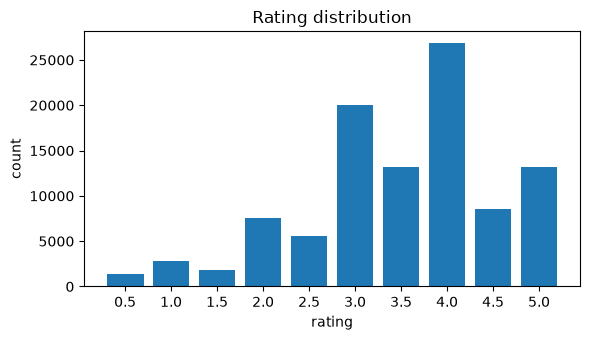

mean rating: 3.501556983616962  share >= 4: 0.4817723828791305


In [16]:
counts = ratings["rating"].value_counts().sort_index()
plt.figure(figsize=(6, 3.5))
plt.bar(counts.index.astype(str), counts.values)
plt.xlabel("rating")
plt.ylabel("count")
plt.title("Rating distribution")
plt.tight_layout()
plt.savefig(FIG_DIR + "/01_rating_distribution.png")
plt.show()
print("mean rating:", ratings["rating"].mean(), " share >= 4:", (ratings["rating"] >= 4).mean())

## Ratings per user and per movie

count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64
count    9724.000000
mean       10.369807
std        22.401005
min         1.000000
25%         1.000000
50%         3.000000
75%         9.000000
max       329.000000
dtype: float64
movies with less than 5 ratings: 0.6246400658165364
movies with exactly 1 rating: 0.3543809132044426


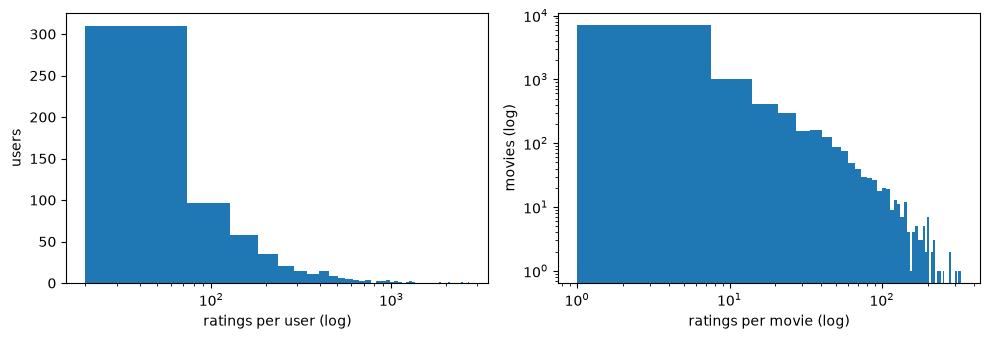

In [17]:
per_user = ratings.groupby("userId").size()
per_movie = ratings.groupby("movieId").size()
print(per_user.describe())
print(per_movie.describe())
print("movies with less than 5 ratings:", (per_movie < 5).mean())
print("movies with exactly 1 rating:", (per_movie == 1).mean())

plt.figure(figsize=(10, 3.5))
plt.subplot(1, 2, 1)
plt.hist(per_user, bins=50)
plt.xscale("log")
plt.xlabel("ratings per user (log)")
plt.ylabel("users")
plt.subplot(1, 2, 2)
plt.hist(per_movie, bins=50)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("ratings per movie (log)")
plt.ylabel("movies (log)")
plt.tight_layout()
plt.savefig(FIG_DIR + "/02_activity_histograms.png")
plt.show()

## Popular movies, genres and tags

In [18]:
titles = movies.set_index("movieId")["title"]
top = per_movie.sort_values(ascending=False).head(10)
pd.DataFrame({"title": titles[top.index].values, "n_ratings": top.values})

,title,n_ratings
0,Forrest Gump (1994),329
1,"Shawshank Redemption, The (1994)",317
2,Pulp Fiction (1994),307
3,"Silence of the Lambs, The (1991)",279
4,"Matrix, The (1999)",278
5,Star Wars: Episode IV - A New Hope (1977),251
6,Jurassic Park (1993),238
7,Braveheart (1995),237
8,Terminator 2: Judgment Day (1991),224
9,Schindler's List (1993),220


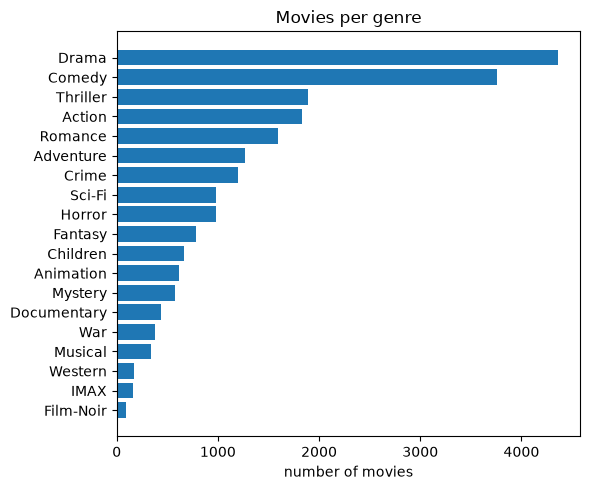

In [19]:
genre_counts = movies["genre_list"].explode().value_counts()
genre_counts = genre_counts.drop("(no genres listed)").sort_values()
plt.figure(figsize=(6, 5))
plt.barh(genre_counts.index, genre_counts.values)
plt.xlabel("number of movies")
plt.title("Movies per genre")
plt.tight_layout()
plt.show()

tag
in netflix queue      131
atmospheric            41
funny                  24
superhero              24
surreal                24
thought-provoking      24
sci-fi                 23
disney                 23
quirky                 22
religion               22
dark comedy            21
suspense               21
psychology             21
twist ending           20
visually appealing     20
Name: count, dtype: int64
users who tagged: 58 of 610
movies with tags: 1572 of 9742
share of tags from the top user: 0.4091773011132229


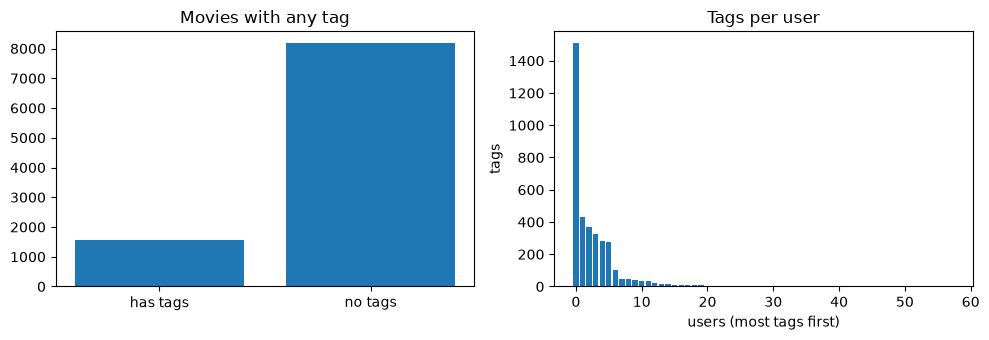

In [20]:
print(tags["tag"].value_counts().head(15))

tags_per_user = tags["userId"].value_counts()
n_tagged = tags["movieId"].nunique()
print("users who tagged:", len(tags_per_user), "of", ratings["userId"].nunique())
print("movies with tags:", n_tagged, "of", len(movies))
print("share of tags from the top user:", tags_per_user.iloc[0] / len(tags))

plt.figure(figsize=(10, 3.5))
plt.subplot(1, 2, 1)
plt.bar(["has tags", "no tags"], [n_tagged, len(movies) - n_tagged])
plt.title("Movies with any tag")
plt.subplot(1, 2, 2)
plt.bar(range(len(tags_per_user)), tags_per_user.values)
plt.xlabel("users (most tags first)")
plt.ylabel("tags")
plt.title("Tags per user")
plt.tight_layout()
plt.savefig(FIG_DIR + "/05_tag_sparsity.png")
plt.show()

## Time
Most users rate everything in a short time, so a time based split will put many users completely in the test set.

1996-03-29 18:36:55 to 2018-09-24 14:27:30


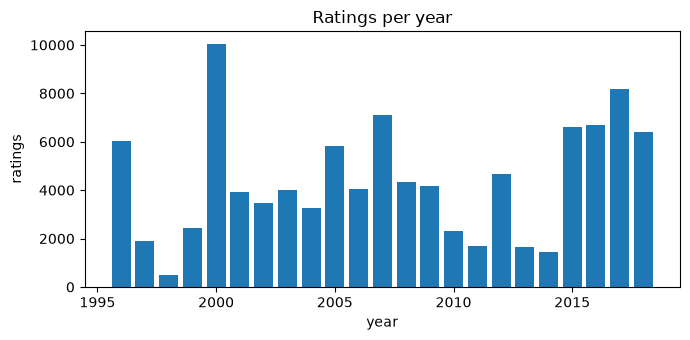

In [21]:
print(ratings["date"].min(), "to", ratings["date"].max())

by_year = ratings.groupby(ratings["date"].dt.year).size()
plt.figure(figsize=(7, 3.5))
plt.bar(by_year.index, by_year.values)
plt.xlabel("year")
plt.ylabel("ratings")
plt.title("Ratings per year")
plt.tight_layout()
plt.savefig(FIG_DIR + "/03_ratings_per_year.png")
plt.show()

users who rated everything within one day: 0.5934426229508196


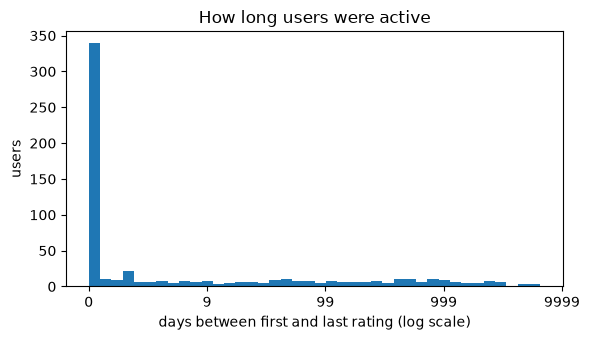

In [22]:
# days between each user's first and last rating
days = ratings.groupby("userId")["timestamp"].agg(lambda s: (s.max() - s.min()) / 86400)
print("users who rated everything within one day:", (days < 1).mean())

plt.figure(figsize=(6, 3.5))
plt.hist(np.log10(days + 1), bins=40)
plt.xticks([0, 1, 2, 3, 4], ["0", "9", "99", "999", "9999"])
plt.xlabel("days between first and last rating (log scale)")
plt.ylabel("users")
plt.title("How long users were active")
plt.tight_layout()
plt.savefig(FIG_DIR + "/04_user_time_span.png")
plt.show()

## What this means for the models
1. A few movies get most of the ratings, so the popularity baseline will be strong and we need coverage/novelty metrics too.
2. Most movies have very few ratings, so they will be hard to recommend (cold-start items).
3. The train/test split has to be by time, and tags after the cutoff must not be used.
4. Tags are too sparse to use as the main signal, better for explanations.

## Rules to avoid leakage
1. **Time.** A model may only use ratings and tags from before the time it predicts. Pick a cutoff, fit on data up to it, and test on data after it. Tune on a validation period before the test period and use the test period once.
2. **Statistics.** Popularity counts, mean ratings, similarity matrices, tag lists and genre profiles must be computed from the training data only. `serving_model = Recommender(ratings)` in `backend/main.py` uses all the data. That is fine for the app but must not be used for evaluation.
3. **Tags.** Tags added after the cutoff belong to the test period, so filter them by `timestamp` too.
4. **Filters.** Don't remove movies or users based on counts that include test-period ratings.

## Known limits
- **Who is in the data.** Users are MovieLens members who chose to use a movie recommendation site. There is no demographic information, so we cannot check whether they represent a wider group.
- **Only active users.** Every user has at least 20 ratings, so light users are not in the data and "new user" tests here are with people who later became active.
- **Ratings are not random.** People rate movies they chose to watch, often because the site suggested them, so past recommendations shape the data (exposure bias).
- **Small data.** About 600 users and 100k ratings means wide uncertainty for any metric computed on a small number of test users.
- **Hand typed metadata.** Titles, genres and years can contain mistakes.
- **Tags.** They come from a few users, and some describe the user's behaviour instead of the movie (the most common one is "in netflix queue").
- **Privacy.** Ids are anonymous, but a rating history can still be unique.